# ============================================================================
# TASK 1: BUSINESS SALES PERFORMANCE ANALYTICS
# Future Interns - Data Science & Analytics Internship
# Author: Your Name
# Date: 2026-09-25
# ============================================================================

# Install required libraries if needed (run once):
# !pip install pandas numpy matplotlib seaborn plotly scikit-learn

In [1]:
# CELL 1: IMPORT LIBRARIES
# ============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from datetime import datetime, timedelta
import warnings
warnings.filterwarnings('ignore')

# Set style for visualizations
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print("✓ All libraries imported successfully!")

✓ All libraries imported successfully!


In [2]:
# CELL 2: GENERATE SAMPLE SALES DATA
# ============================================================================
"""
Since no dataset was provided, we generate realistic sample sales data.
This mimics real business sales data with:
- 3000+ transactions
- Multiple products and categories
- Different regions
- Date range: 90 days
"""

np.random.seed(42)

# Define data parameters
products = ['Laptop', 'Mouse', 'Keyboard', 'Monitor', 'Headphones', 
            'Webcam', 'USB Hub', 'Phone Case', 'Charger', 'Screen Protector',
            'Tablet', 'Stylus', 'HDMI Cable', 'Desk Lamp', 'Phone Stand']

categories = {
    'Laptop': 'Electronics', 'Tablet': 'Electronics',
    'Mouse': 'Accessories', 'Keyboard': 'Accessories', 'USB Hub': 'Accessories',
    'Monitor': 'Peripherals', 'Headphones': 'Audio', 'Webcam': 'Audio',
    'Phone Case': 'Mobile', 'Charger': 'Mobile', 'Screen Protector': 'Mobile', 'Stylus': 'Mobile',
    'HDMI Cable': 'Cables', 'Desk Lamp': 'Office Supplies', 'Phone Stand': 'Office Supplies'
}

regions = ['North', 'South', 'East', 'West', 'Northeast', 'Central']

# Product prices (realistic)
prices = {
    'Laptop': 800, 'Monitor': 350, 'Tablet': 400,
    'Keyboard': 120, 'Mouse': 50, 'Headphones': 150,
    'Webcam': 80, 'Phone Case': 15, 'Charger': 25,
    'Screen Protector': 10, 'Stylus': 70, 'USB Hub': 45,
    'HDMI Cable': 20, 'Desk Lamp': 40, 'Phone Stand': 18
}

# Generate dates (90 days)
start_date = datetime(2026, 7, 1)
dates = [start_date + timedelta(days=x) for x in range(90)]

# Generate sales data
n_records = 3000
data = {
    'Order_ID': [f'ORD{i:05d}' for i in range(1, n_records + 1)],
    'Date': np.random.choice(dates, n_records),
    'Product': np.random.choice(products, n_records),
    'Quantity': np.random.randint(1, 8, n_records),
    'Region': np.random.choice(regions, n_records),
    'Customer_ID': np.random.randint(1000, 2500, n_records),
}

# Create DataFrame
df = pd.DataFrame(data)

# Add category and price columns
df['Category'] = df['Product'].map(categories)
df['Unit_Price'] = df['Product'].map(prices)
df['Revenue'] = df['Quantity'] * df['Unit_Price']

# Add cost (60% of price for profit calculation)
df['Cost'] = df['Quantity'] * (df['Unit_Price'] * 0.6)
df['Profit'] = df['Revenue'] - df['Cost']

# Sort by date
df = df.sort_values('Date').reset_index(drop=True)

print(f"✓ Sample dataset generated with {len(df)} records")
print(f"\nDataset Preview:")
print(df.head(10))

✓ Sample dataset generated with 3000 records

Dataset Preview:
   Order_ID       Date           Product  Quantity     Region  Customer_ID  \
0  ORD00105 2026-07-01         Desk Lamp         5      South         2220   
1  ORD00474 2026-07-01            Stylus         6  Northeast         2361   
2  ORD01118 2026-07-01            Stylus         2    Central         1079   
3  ORD01126 2026-07-01  Screen Protector         6      South         2369   
4  ORD00848 2026-07-01           Monitor         3  Northeast         2264   
5  ORD02034 2026-07-01            Laptop         3      South         1591   
6  ORD01182 2026-07-01           Monitor         1    Central         1387   
7  ORD02965 2026-07-01  Screen Protector         4       East         1376   
8  ORD01199 2026-07-01            Webcam         4    Central         2435   
9  ORD01207 2026-07-01        HDMI Cable         2       East         1272   

          Category  Unit_Price  Revenue    Cost  Profit  
0  Office Supplies  

In [3]:
# ============================================================================
# CELL 3: DATA EXPLORATION & CLEANING
# ============================================================================

print("\n" + "="*60)
print("DATA EXPLORATION & QUALITY CHECK")
print("="*60)

# Basic info
print(f"\nDataset Shape: {df.shape}")
print(f"\nData Types:\n{df.dtypes}")
print(f"\nMissing Values:\n{df.isnull().sum()}")
print(f"\nBasic Statistics:\n{df.describe()}")

# Data quality checks
print(f"\nUnique Products: {df['Product'].nunique()}")
print(f"Unique Regions: {df['Region'].nunique()}")
print(f"Unique Categories: {df['Category'].nunique()}")
print(f"Date Range: {df['Date'].min()} to {df['Date'].max()}")

# Clean data (remove any nulls)
df = df.dropna()
print(f"\n✓ Data cleaned. Final records: {len(df)}")



DATA EXPLORATION & QUALITY CHECK

Dataset Shape: (3000, 11)

Data Types:
Order_ID               object
Date           datetime64[ns]
Product                object
Quantity                int32
Region                 object
Customer_ID             int32
Category               object
Unit_Price              int64
Revenue                 int64
Cost                  float64
Profit                float64
dtype: object

Missing Values:
Order_ID       0
Date           0
Product        0
Quantity       0
Region         0
Customer_ID    0
Category       0
Unit_Price     0
Revenue        0
Cost           0
Profit         0
dtype: int64

Basic Statistics:
                                Date     Quantity  Customer_ID   Unit_Price  \
count                           3000  3000.000000  3000.000000  3000.000000   
mean   2026-08-13 05:42:43.199999744     4.048000  1750.019000   151.126667   
min              2026-07-01 00:00:00     1.000000  1000.000000    10.000000   
25%              2026-07-21 00

In [4]:
# ============================================================================
# CELL 4: KEY PERFORMANCE INDICATORS (KPIs)
# ============================================================================

print("\n" + "="*60)
print("KEY PERFORMANCE INDICATORS (KPIs)")
print("="*60)

total_revenue = df['Revenue'].sum()
total_profit = df['Profit'].sum()
total_orders = len(df)
avg_order_value = df['Revenue'].mean()
profit_margin = (total_profit / total_revenue) * 100
unique_customers = df['Customer_ID'].nunique()
avg_revenue_per_customer = total_revenue / unique_customers

print(f"""
📊 BUSINESS METRICS:
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Total Revenue:              ₹{total_revenue:,.2f}
Total Profit:               ₹{total_profit:,.2f}
Total Orders:               {total_orders:,}
Average Order Value (AOV):  ₹{avg_order_value:,.2f}
Profit Margin:              {profit_margin:.2f}%
Unique Customers:           {unique_customers:,}
Revenue per Customer:       ₹{avg_revenue_per_customer:,.2f}
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
""")


KEY PERFORMANCE INDICATORS (KPIs)

📊 BUSINESS METRICS:
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Total Revenue:              ₹1,825,283.00
Total Profit:               ₹730,113.20
Total Orders:               3,000
Average Order Value (AOV):  ₹608.43
Profit Margin:              40.00%
Unique Customers:           1,286
Revenue per Customer:       ₹1,419.35
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━



In [5]:
# CELL 5: REVENUE TRENDS ANALYSIS
# ============================================================================

print("\n" + "="*60)
print("REVENUE TRENDS ANALYSIS")
print("="*60)

# Daily revenue
daily_revenue = df.groupby(df['Date'].dt.date)['Revenue'].agg(['sum', 'count', 'mean'])
daily_revenue.columns = ['Daily_Revenue', 'Orders', 'Avg_Order_Value']
print("\nDaily Revenue Summary:")
print(daily_revenue.head(10))

# Weekly revenue
df['Week'] = df['Date'].dt.isocalendar().week
weekly_revenue = df.groupby('Week')['Revenue'].sum().reset_index()
print(f"\nWeekly Revenue:\n{weekly_revenue}")

# Calculate growth rate
weekly_revenue['Revenue_Growth_%'] = weekly_revenue['Revenue'].pct_change() * 100
print("\nWith Growth Rate:")
print(weekly_revenue)

# ============================================================================



REVENUE TRENDS ANALYSIS

Daily Revenue Summary:
            Daily_Revenue  Orders  Avg_Order_Value
Date                                              
2026-07-01          22528      39       577.641026
2026-07-02          25098      42       597.571429
2026-07-03          20728      40       518.200000
2026-07-04          10630      35       303.714286
2026-07-05          26813      40       670.325000
2026-07-06          23200      30       773.333333
2026-07-07          13832      31       446.193548
2026-07-08          17781      43       413.511628
2026-07-09          22721      33       688.515152
2026-07-10          19963      31       643.967742

Weekly Revenue:
    Week  Revenue
0     27   105797
1     28   137151
2     29   147137
3     30   153331
4     31   185435
5     32   159402
6     33   121032
7     34   122433
8     35   170696
9     36   123509
10    37   116439
11    38   113549
12    39   145975
13    40    23397

With Growth Rate:
    Week  Revenue  Revenue_Growth


📈 Generating Visualization 1: Revenue Trends...
✓ Saved: revenue_trends.png


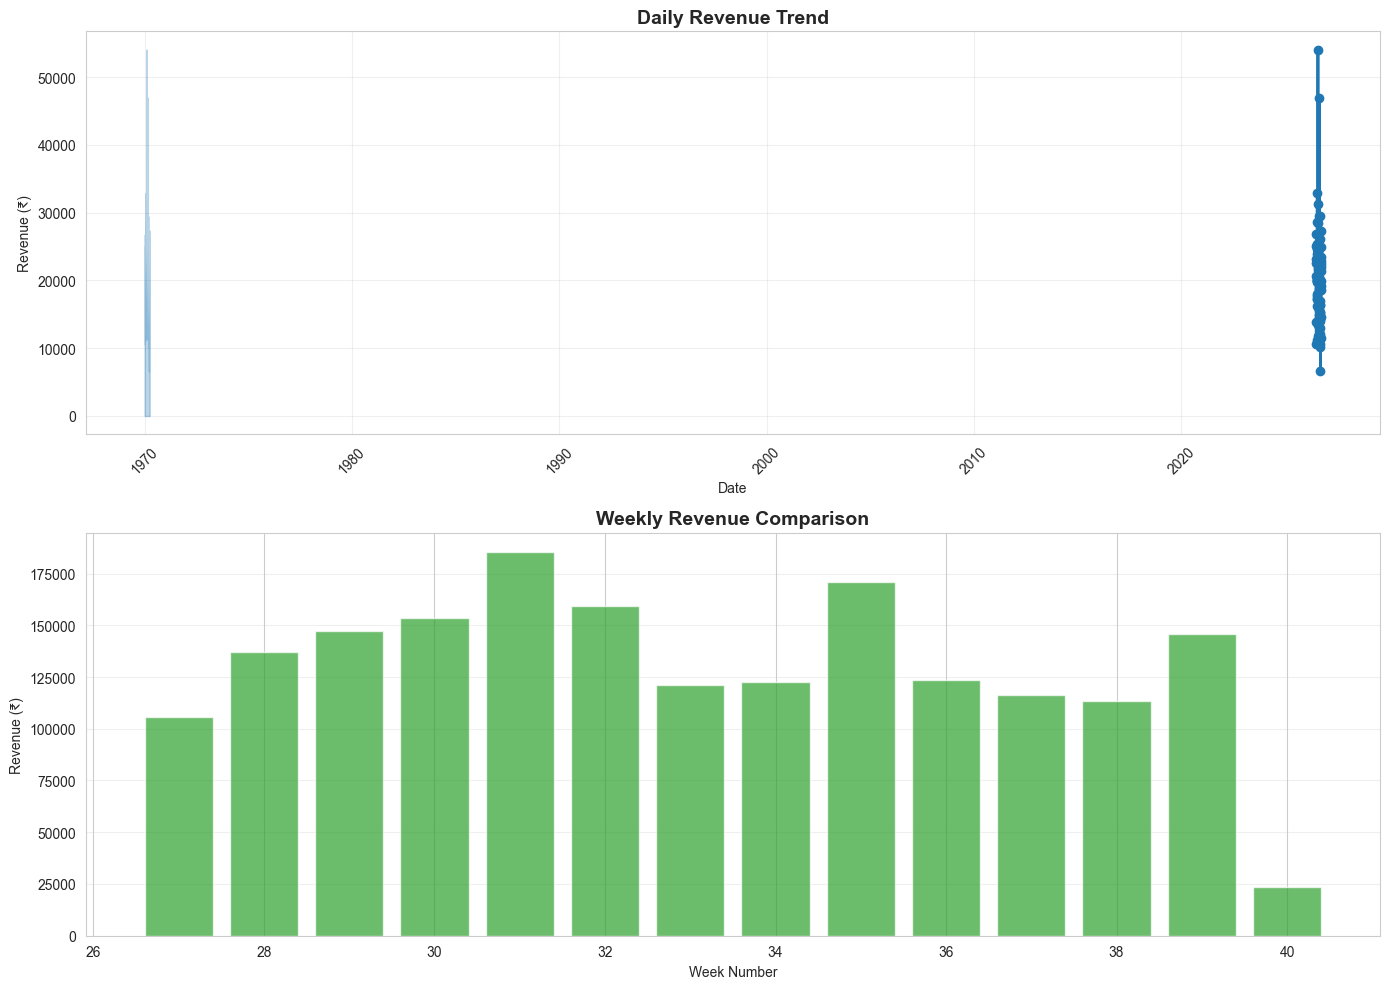

In [6]:
# CELL 6: VISUALIZATION 1 - REVENUE TRENDS
# ============================================================================

print("\n📈 Generating Visualization 1: Revenue Trends...")

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Daily revenue trend
daily_revenue_plot = df.groupby(df['Date'].dt.date)['Revenue'].sum()
axes[0].plot(daily_revenue_plot.index, daily_revenue_plot.values, marker='o', linewidth=2, color='#1f77b4')
axes[0].fill_between(range(len(daily_revenue_plot)), daily_revenue_plot.values, alpha=0.3, color='#1f77b4')
axes[0].set_title('Daily Revenue Trend', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Revenue (₹)')
axes[0].grid(True, alpha=0.3)
plt.setp(axes[0].xaxis.get_majorticklabels(), rotation=45)

# Weekly revenue
axes[1].bar(weekly_revenue['Week'], weekly_revenue['Revenue'], color='#2ca02c', alpha=0.7)
axes[1].set_title('Weekly Revenue Comparison', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Week Number')
axes[1].set_ylabel('Revenue (₹)')
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('revenue_trends.png', dpi=300, bbox_inches='tight')
print("✓ Saved: revenue_trends.png")
plt.show()

# ============================================================================


In [7]:
# CELL 7: TOP-SELLING PRODUCTS ANALYSIS
# ============================================================================

print("\n" + "="*60)
print("TOP-SELLING PRODUCTS ANALYSIS")
print("="*60)

# By Revenue
top_products_revenue = df.groupby('Product')['Revenue'].sum().sort_values(ascending=False)
print("\nTop 10 Products by Revenue:")
print(top_products_revenue.head(10))

# By Quantity
top_products_qty = df.groupby('Product')['Quantity'].sum().sort_values(ascending=False)
print("\nTop 10 Products by Quantity Sold:")
print(top_products_qty.head(10))

# By Order Count
product_orders = df.groupby('Product').size().sort_values(ascending=False)
print("\nTop 10 Products by Order Count:")
print(product_orders.head(10))

# ============================================================================



TOP-SELLING PRODUCTS ANALYSIS

Top 10 Products by Revenue:
Product
Laptop        708800
Tablet        324400
Monitor       278600
Headphones    109200
Keyboard      106320
Webcam         64160
Stylus         57960
Mouse          37750
USB Hub        34110
Desk Lamp      31680
Name: Revenue, dtype: int64

Top 10 Products by Quantity Sold:
Product
Phone Case     914
Keyboard       886
Laptop         886
HDMI Cable     862
Stylus         828
Tablet         811
Webcam         802
Phone Stand    801
Monitor        796
Desk Lamp      792
Name: Quantity, dtype: int32

Top 10 Products by Order Count:
Product
Laptop         217
HDMI Cable     216
Phone Case     215
Tablet         212
Webcam         212
Keyboard       210
Phone Stand    205
Stylus         202
Charger        199
Monitor        194
dtype: int64



📊 Generating Visualization 2: Top Products...
✓ Saved: top_products.png


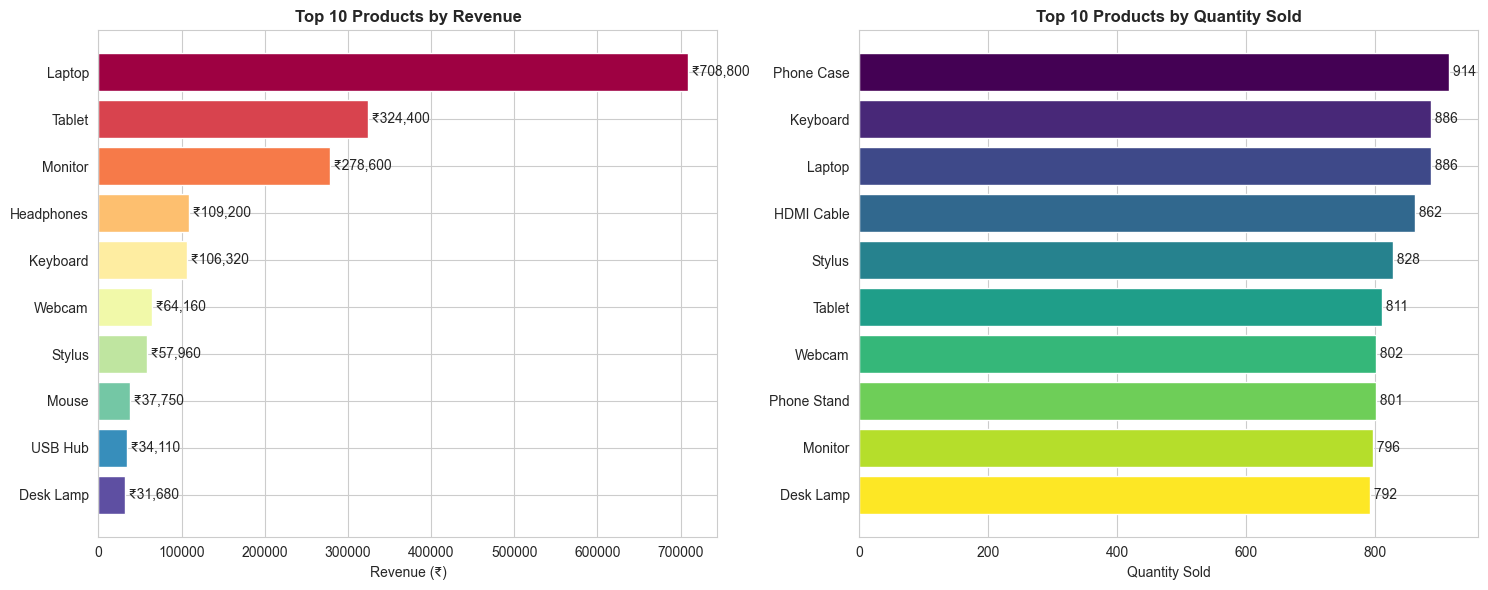

In [9]:
# CELL 8: VISUALIZATION 2 - TOP PRODUCTS
# ============================================================================

print("\n📊 Generating Visualization 2: Top Products...")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Top 10 by Revenue
top10_revenue = top_products_revenue.head(10)
colors_revenue = plt.cm.Spectral(np.linspace(0, 1, 10))
axes[0].barh(range(len(top10_revenue)), top10_revenue.values, color=colors_revenue)
axes[0].set_yticks(range(len(top10_revenue)))
axes[0].set_yticklabels(top10_revenue.index)
axes[0].set_title('Top 10 Products by Revenue', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Revenue (₹)')
axes[0].invert_yaxis()
for i, v in enumerate(top10_revenue.values):
    axes[0].text(v, i, f' ₹{v:,.0f}', va='center')

# Top 10 by Quantity
top10_qty = top_products_qty.head(10)
colors_qty = plt.cm.viridis(np.linspace(0, 1, 10))
axes[1].barh(range(len(top10_qty)), top10_qty.values, color=colors_qty)
axes[1].set_yticks(range(len(top10_qty)))
axes[1].set_yticklabels(top10_qty.index)
axes[1].set_title('Top 10 Products by Quantity Sold', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Quantity Sold')
axes[1].invert_yaxis()
for i, v in enumerate(top10_qty.values):
    axes[1].text(v, i, f' {v}', va='center')

plt.tight_layout()
plt.savefig('top_products.png', dpi=300, bbox_inches='tight')
print("✓ Saved: top_products.png")
plt.show()

# ============================================================================


In [10]:
# CELL 9: CATEGORY ANALYSIS
# ============================================================================

print("\n" + "="*60)
print("CATEGORY PERFORMANCE ANALYSIS")
print("="*60)

category_stats = df.groupby('Category').agg({
    'Revenue': ['sum', 'mean', 'count'],
    'Profit': 'sum',
    'Quantity': 'sum'
}).round(2)

category_stats.columns = ['Total_Revenue', 'Avg_Order_Value', 'Order_Count', 'Total_Profit', 'Qty_Sold']
category_stats['Profit_Margin_%'] = (category_stats['Total_Profit'] / category_stats['Total_Revenue'] * 100).round(2)
category_stats = category_stats.sort_values('Total_Revenue', ascending=False)

print("\nCategory Performance Summary:")
print(category_stats)

# ============================================================================



CATEGORY PERFORMANCE ANALYSIS

Category Performance Summary:
                 Total_Revenue  Avg_Order_Value  Order_Count  Total_Profit  \
Category                                                                     
Electronics            1033200          2408.39          429      413280.0   
Peripherals             278600          1436.08          194      111440.0   
Accessories             178180           310.96          573       71272.0   
Audio                   173360           434.49          399       69344.0   
Mobile                   98605           123.72          797       39442.0   
Office Supplies          46098           117.60          392       18439.2   
Cables                   17240            79.81          216        6896.0   

                 Qty_Sold  Profit_Margin_%  
Category                                    
Electronics          1697             40.0  
Peripherals           796             40.0  
Accessories          2399             40.0  
Audio     


📈 Generating Visualization 3: Category Performance...
✓ Saved: category_performance.png


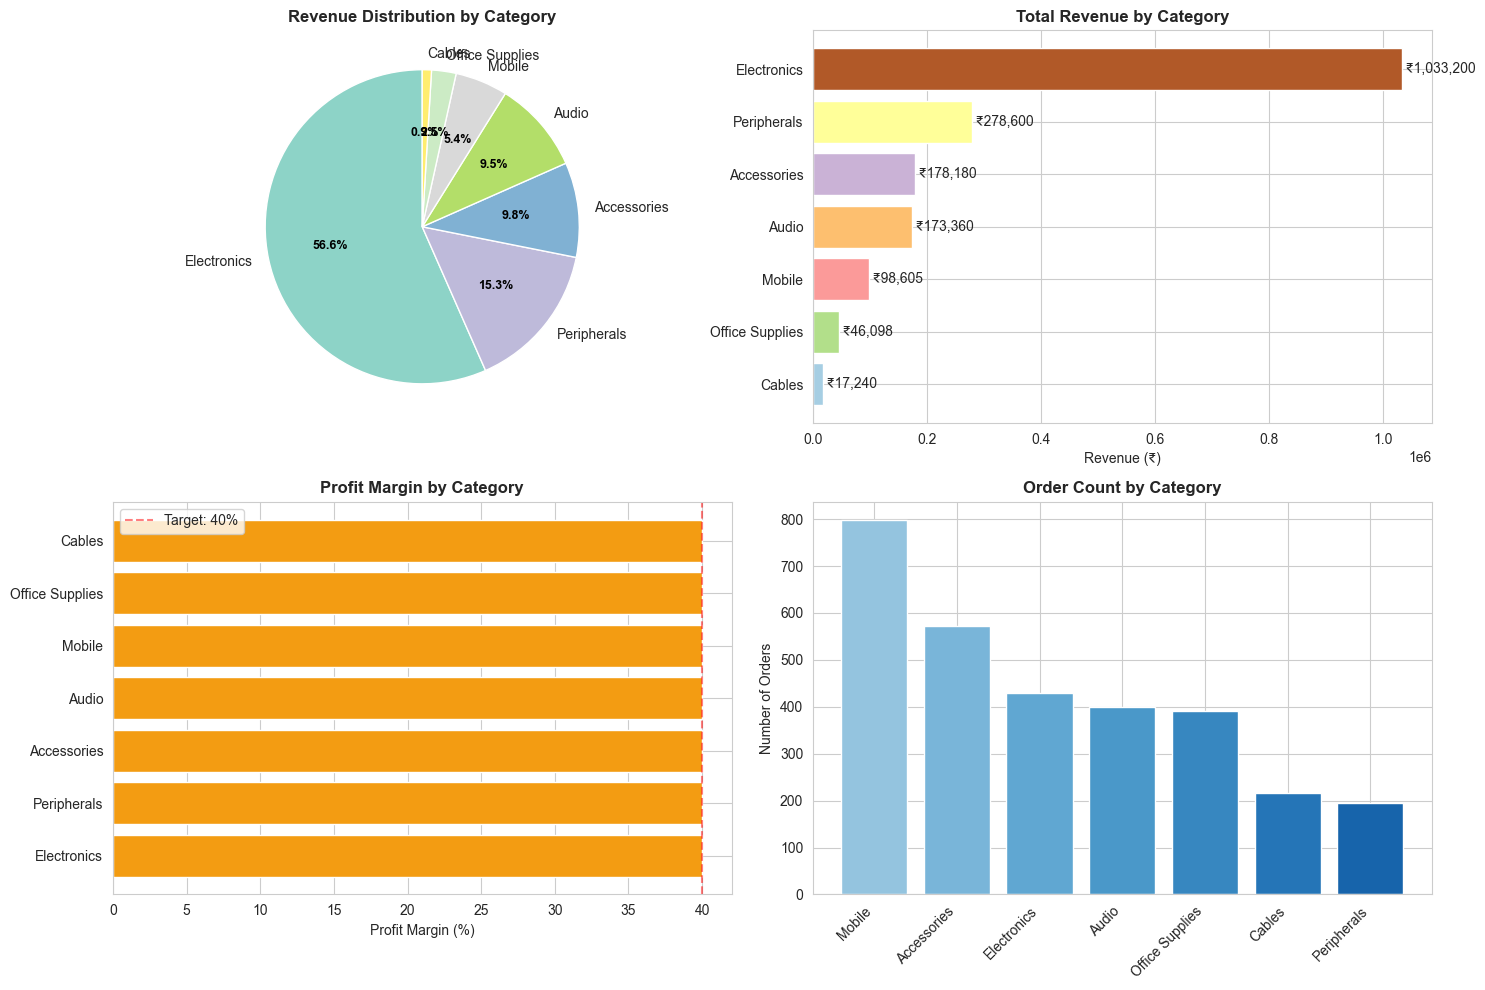

In [11]:
# CELL 10: VISUALIZATION 3 - CATEGORY BREAKDOWN
# ============================================================================

print("\n📈 Generating Visualization 3: Category Performance...")

fig = plt.figure(figsize=(15, 10))
gs = fig.add_gridspec(2, 2)

# Revenue by Category - Pie Chart
ax1 = fig.add_subplot(gs[0, 0])
colors = plt.cm.Set3(np.linspace(0, 1, len(category_stats)))
wedges, texts, autotexts = ax1.pie(category_stats['Total_Revenue'], labels=category_stats.index, 
                                     autopct='%1.1f%%', colors=colors, startangle=90)
ax1.set_title('Revenue Distribution by Category', fontweight='bold', fontsize=12)
for autotext in autotexts:
    autotext.set_color('black')
    autotext.set_fontsize(9)
    autotext.set_fontweight('bold')

# Category Revenue - Bar
ax2 = fig.add_subplot(gs[0, 1])
category_revenue = category_stats['Total_Revenue'].sort_values(ascending=True)
ax2.barh(category_revenue.index, category_revenue.values, color=plt.cm.Paired(np.linspace(0, 1, len(category_revenue))))
ax2.set_title('Total Revenue by Category', fontweight='bold', fontsize=12)
ax2.set_xlabel('Revenue (₹)')
for i, v in enumerate(category_revenue.values):
    ax2.text(v, i, f' ₹{v:,.0f}', va='center')

# Profit Margin by Category
ax3 = fig.add_subplot(gs[1, 0])
margin_data = category_stats['Profit_Margin_%'].sort_values(ascending=True)
colors_margin = ['#2ecc71' if x > 40 else '#f39c12' for x in margin_data.values]
ax3.barh(margin_data.index, margin_data.values, color=colors_margin)
ax3.set_title('Profit Margin by Category', fontweight='bold', fontsize=12)
ax3.set_xlabel('Profit Margin (%)')
ax3.axvline(x=40, color='red', linestyle='--', alpha=0.5, label='Target: 40%')
ax3.legend()

# Order Count by Category
ax4 = fig.add_subplot(gs[1, 1])
order_data = category_stats['Order_Count'].sort_values(ascending=False)
ax4.bar(range(len(order_data)), order_data.values, color=plt.cm.Blues(np.linspace(0.4, 0.8, len(order_data))))
ax4.set_xticks(range(len(order_data)))
ax4.set_xticklabels(order_data.index, rotation=45, ha='right')
ax4.set_title('Order Count by Category', fontweight='bold', fontsize=12)
ax4.set_ylabel('Number of Orders')

plt.tight_layout()
plt.savefig('category_performance.png', dpi=300, bbox_inches='tight')
print("✓ Saved: category_performance.png")
plt.show()

# ============================================================================


In [12]:
# CELL 11: REGIONAL PERFORMANCE ANALYSIS
# ============================================================================

print("\n" + "="*60)
print("REGIONAL PERFORMANCE ANALYSIS")
print("="*60)

regional_stats = df.groupby('Region').agg({
    'Revenue': ['sum', 'mean', 'count'],
    'Profit': 'sum',
    'Quantity': 'sum',
    'Customer_ID': 'nunique'
}).round(2)

regional_stats.columns = ['Total_Revenue', 'Avg_Order_Value', 'Order_Count', 'Total_Profit', 'Qty_Sold', 'Unique_Customers']
regional_stats['Profit_Margin_%'] = (regional_stats['Total_Profit'] / regional_stats['Total_Revenue'] * 100).round(2)
regional_stats['Revenue_per_Customer'] = (regional_stats['Total_Revenue'] / regional_stats['Unique_Customers']).round(2)
regional_stats = regional_stats.sort_values('Total_Revenue', ascending=False)

print("\nRegional Performance Summary:")
print(regional_stats)

# ============================================================================



REGIONAL PERFORMANCE ANALYSIS

Regional Performance Summary:
           Total_Revenue  Avg_Order_Value  Order_Count  Total_Profit  \
Region                                                                 
East              322972           661.83          488      129188.8   
South             316921           587.98          539      126768.4   
North             314881           599.77          525      125952.4   
Northeast         299503           615.00          487      119801.2   
Central           292552           599.49          488      117020.8   
West              278454           588.70          473      111381.6   

           Qty_Sold  Unique_Customers  Profit_Margin_%  Revenue_per_Customer  
Region                                                                        
East           1976               412             40.0                783.91  
South          2205               450             40.0                704.27  
North          2177               444        


📊 Generating Visualization 4: Regional Performance...
✓ Saved: regional_performance.png


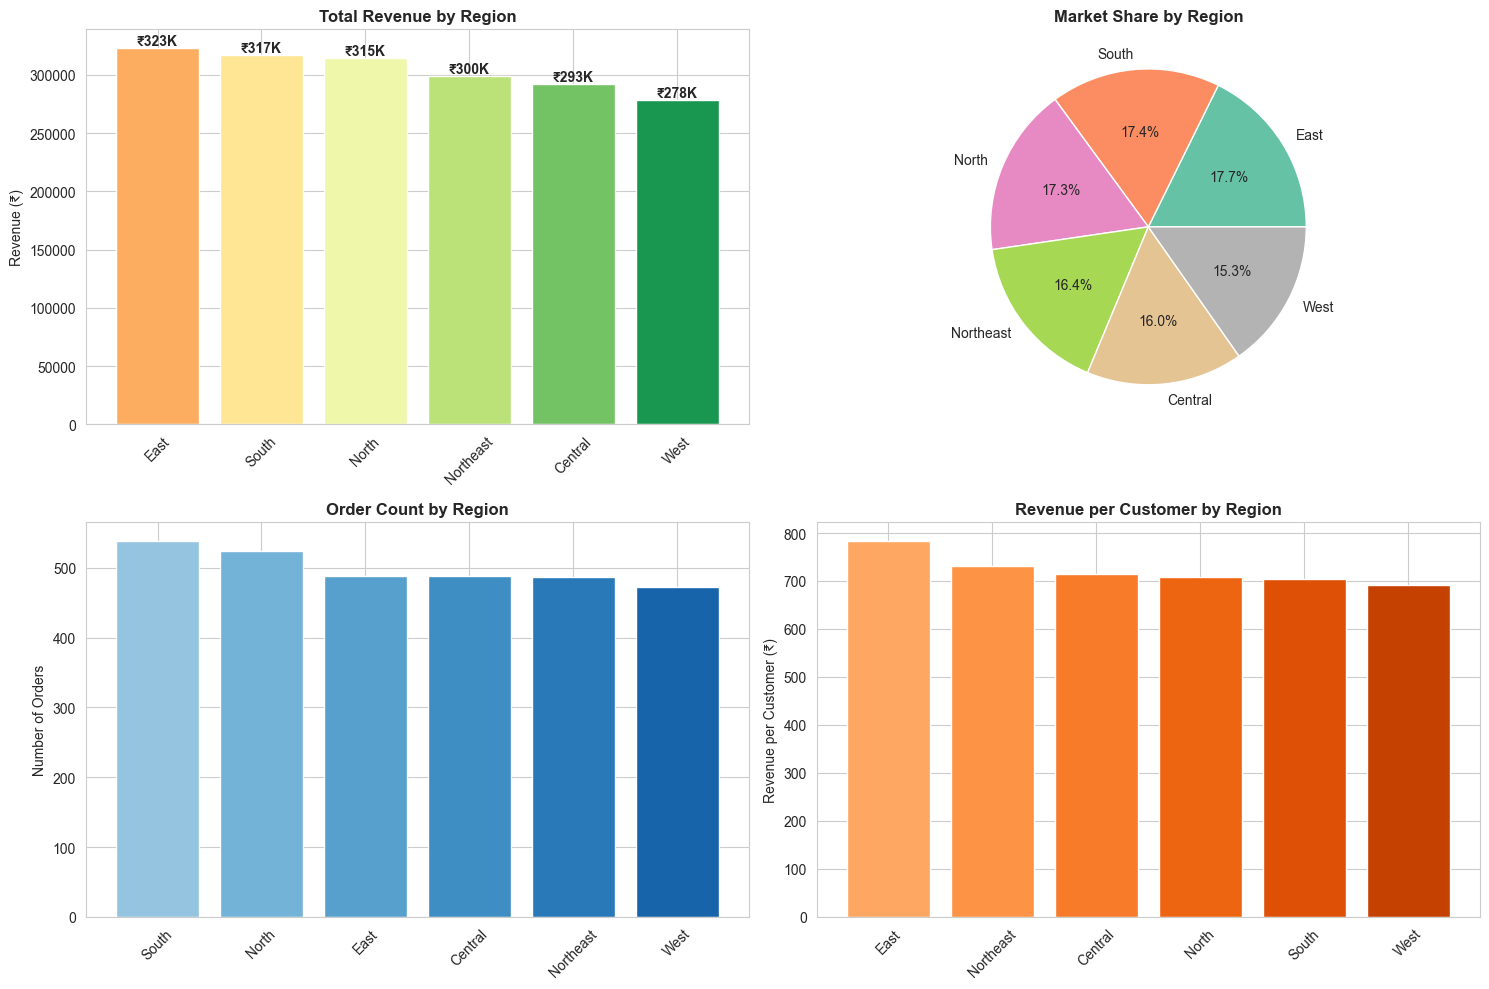

In [13]:
# CELL 12: VISUALIZATION 4 - REGIONAL PERFORMANCE
# ============================================================================

print("\n📊 Generating Visualization 4: Regional Performance...")

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Revenue by Region
region_revenue = regional_stats['Total_Revenue'].sort_values(ascending=False)
colors_region = plt.cm.RdYlGn(np.linspace(0.3, 0.9, len(region_revenue)))
axes[0, 0].bar(region_revenue.index, region_revenue.values, color=colors_region)
axes[0, 0].set_title('Total Revenue by Region', fontweight='bold', fontsize=12)
axes[0, 0].set_ylabel('Revenue (₹)')
axes[0, 0].set_xticklabels(region_revenue.index, rotation=45)
for i, v in enumerate(region_revenue.values):
    axes[0, 0].text(i, v, f'₹{v/1000:.0f}K', ha='center', va='bottom', fontweight='bold')

# Market Share
region_share = (regional_stats['Total_Revenue'] / regional_stats['Total_Revenue'].sum() * 100).sort_values(ascending=False)
axes[0, 1].pie(region_share.values, labels=region_share.index, autopct='%1.1f%%', 
               colors=plt.cm.Set2(np.linspace(0, 1, len(region_share))))
axes[0, 1].set_title('Market Share by Region', fontweight='bold', fontsize=12)

# Orders by Region
region_orders = regional_stats['Order_Count'].sort_values(ascending=False)
axes[1, 0].bar(region_orders.index, region_orders.values, color=plt.cm.Blues(np.linspace(0.4, 0.8, len(region_orders))))
axes[1, 0].set_title('Order Count by Region', fontweight='bold', fontsize=12)
axes[1, 0].set_ylabel('Number of Orders')
axes[1, 0].set_xticklabels(region_orders.index, rotation=45)

# Revenue per Customer by Region
revenue_per_cust = regional_stats['Revenue_per_Customer'].sort_values(ascending=False)
axes[1, 1].bar(revenue_per_cust.index, revenue_per_cust.values, 
               color=plt.cm.Oranges(np.linspace(0.4, 0.8, len(revenue_per_cust))))
axes[1, 1].set_title('Revenue per Customer by Region', fontweight='bold', fontsize=12)
axes[1, 1].set_ylabel('Revenue per Customer (₹)')
axes[1, 1].set_xticklabels(revenue_per_cust.index, rotation=45)

plt.tight_layout()
plt.savefig('regional_performance.png', dpi=300, bbox_inches='tight')
print("✓ Saved: regional_performance.png")
plt.show()

# ============================================================================


In [14]:
# CELL 13: KEY INSIGHTS & RECOMMENDATIONS
# ============================================================================

print("\n" + "="*60)
print("KEY INSIGHTS & ACTIONABLE RECOMMENDATIONS")
print("="*60)

# Top insights
top_product = top_products_revenue.index[0]
top_category = category_stats.index[0]
top_region = regional_stats.index[0]

print(f"""
🎯 KEY FINDINGS:
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

1️⃣  REVENUE PERFORMANCE:
   • Total Revenue Generated: ₹{total_revenue:,.2f}
   • Average Daily Revenue: ₹{total_revenue/90:,.2f}
   • Total Profit: ₹{total_profit:,.2f}
   • Overall Profit Margin: {profit_margin:.2f}%

2️⃣  BEST PERFORMING PRODUCT:
   • Product: {top_product}
   • Revenue: ₹{top_products_revenue.iloc[0]:,.2f}
   • Contribution: {(top_products_revenue.iloc[0]/total_revenue*100):.1f}% of total revenue

3️⃣  BEST PERFORMING CATEGORY:
   • Category: {top_category}
   • Revenue: ₹{category_stats.loc[top_category, 'Total_Revenue']:,.2f}
   • Order Count: {int(category_stats.loc[top_category, 'Order_Count'])}
   • Profit Margin: {category_stats.loc[top_category, 'Profit_Margin_%']:.2f}%

4️⃣  BEST PERFORMING REGION:
   • Region: {top_region}
   • Revenue: ₹{regional_stats.loc[top_region, 'Total_Revenue']:,.2f}
   • Market Share: {(regional_stats.loc[top_region, 'Total_Revenue']/total_revenue*100):.1f}%
   • Unique Customers: {int(regional_stats.loc[top_region, 'Unique_Customers'])}

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

💡 STRATEGIC RECOMMENDATIONS:
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

1. PRODUCT STRATEGY:
   ✓ Focus marketing on top products ({top_product})
   ✓ Cross-sell complementary products to increase AOV
   ✓ Review underperforming products for discontinuation

2. CATEGORY FOCUS:
   ✓ Increase inventory for {top_category} (high demand)
   ✓ Implement bundling strategies
   ✓ Target weak categories with promotional campaigns

3. REGIONAL EXPANSION:
   ✓ Allocate more resources to {top_region} (best performer)
   ✓ Analyze weaker regions for barriers to entry
   ✓ Develop region-specific marketing campaigns

4. CUSTOMER RETENTION:
   ✓ AOV: ₹{avg_order_value:,.2f} - implement upsell campaigns
   ✓ Focus on repeat customers (currently {(df['Customer_ID'].nunique()/len(df)*100):.1f}% unique)
   ✓ Create loyalty programs for high-value regions

5. PROFITABILITY:
   ✓ Current margin: {profit_margin:.2f}% - target improvement to 45%
   ✓ Review pricing strategy for high-demand items
   ✓ Optimize supply chain costs

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
""")

# ============================================================================



KEY INSIGHTS & ACTIONABLE RECOMMENDATIONS

🎯 KEY FINDINGS:
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

1️⃣  REVENUE PERFORMANCE:
   • Total Revenue Generated: ₹1,825,283.00
   • Average Daily Revenue: ₹20,280.92
   • Total Profit: ₹730,113.20
   • Overall Profit Margin: 40.00%

2️⃣  BEST PERFORMING PRODUCT:
   • Product: Laptop
   • Revenue: ₹708,800.00
   • Contribution: 38.8% of total revenue

3️⃣  BEST PERFORMING CATEGORY:
   • Category: Electronics
   • Revenue: ₹1,033,200.00
   • Order Count: 429
   • Profit Margin: 40.00%

4️⃣  BEST PERFORMING REGION:
   • Region: East
   • Revenue: ₹322,972.00
   • Market Share: 17.7%
   • Unique Customers: 412

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

💡 STRATEGIC RECOMMENDATIONS:
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

1. PRODUCT STRATEGY:
   ✓ Focus marketing on top products (Laptop)
   ✓ Cross-sell complementary products to increase AOV
   ✓ Review underperforming products for disc

In [15]:
# CELL 14: EXPORT DATA & CREATE SUMMARY REPORT
# ============================================================================

print("\n" + "="*60)
print("EXPORTING ANALYSIS RESULTS")
print("="*60)

# Export cleaned data
df.to_csv('cleaned_sales_data.csv', index=False)
print("✓ Exported: cleaned_sales_data.csv")

# Export category summary
category_stats.to_csv('category_analysis.csv')
print("✓ Exported: category_analysis.csv")

# Export regional summary
regional_stats.to_csv('regional_analysis.csv')
print("✓ Exported: regional_analysis.csv")

# Export product summary
product_summary = pd.DataFrame({
    'Product': top_products_revenue.index,
    'Revenue': top_products_revenue.values,
    'Quantity_Sold': [top_products_qty[p] for p in top_products_revenue.index],
    'Order_Count': [product_orders[p] for p in top_products_revenue.index]
})
product_summary.to_csv('product_analysis.csv', index=False)
print("✓ Exported: product_analysis.csv")

print("\n" + "="*60)
print("✅ ANALYSIS COMPLETE!")
print("="*60)
print("""
Generated Outputs:
  1. revenue_trends.png - Daily and weekly revenue trends
  2. top_products.png - Top 10 products analysis
  3. category_performance.png - Category breakdown
  4. regional_performance.png - Regional analysis
  5. cleaned_sales_data.csv - Complete dataset
  6. category_analysis.csv - Category metrics
  7. regional_analysis.csv - Regional metrics
  8. product_analysis.csv - Product metrics

Next Steps:
  1. Review all visualizations
  2. Create GitHub repository (FUTURE_DS_01)
  3. Upload notebook and CSV files
  4. Write Analysis_Report.md with findings
  5. Share on LinkedIn with #futureinterns
  6. Submit via Future Interns portal

Remember: This analysis should be ready for a real client!
""")

# ============================================================================



EXPORTING ANALYSIS RESULTS
✓ Exported: cleaned_sales_data.csv
✓ Exported: category_analysis.csv
✓ Exported: regional_analysis.csv
✓ Exported: product_analysis.csv

✅ ANALYSIS COMPLETE!

Generated Outputs:
  1. revenue_trends.png - Daily and weekly revenue trends
  2. top_products.png - Top 10 products analysis
  3. category_performance.png - Category breakdown
  4. regional_performance.png - Regional analysis
  5. cleaned_sales_data.csv - Complete dataset
  6. category_analysis.csv - Category metrics
  7. regional_analysis.csv - Regional metrics
  8. product_analysis.csv - Product metrics

Next Steps:
  1. Review all visualizations
  2. Create GitHub repository (FUTURE_DS_01)
  3. Upload notebook and CSV files
  4. Write Analysis_Report.md with findings
  5. Share on LinkedIn with #futureinterns
  6. Submit via Future Interns portal

Remember: This analysis should be ready for a real client!



In [17]:
from plotly.subplots import make_subplots

In [18]:
# CELL 15: INTERACTIVE DASHBOARD (OPTIONAL - ADVANCED)
# ============================================================================

print("\n" + "="*60)
print("CREATING INTERACTIVE DASHBOARD")
print("="*60)

# Create an interactive dashboard with Plotly
fig = go.Figure()

# Add traces for weekly revenue
fig.add_trace(go.Scatter(
    x=weekly_revenue['Week'],
    y=weekly_revenue['Revenue'],
    mode='lines+markers',
    name='Weekly Revenue',
    line=dict(color='#1f77b4', width=3),
    marker=dict(size=8)
))

fig.update_layout(
    title='Sales Performance Dashboard - Weekly Revenue Trend',
    xaxis_title='Week Number',
    yaxis_title='Revenue (₹)',
    hovermode='x unified',
    template='plotly_white',
    height=500
)

fig.write_html('dashboard_weekly_revenue.html')
print("✓ Created: dashboard_weekly_revenue.html")

# Multi-chart dashboard
fig2 = make_subplots(
    rows=2, cols=2,
    subplot_titles=('Revenue by Category', 'Revenue by Region', 
                    'Orders by Category', 'Top 5 Products'),
    specs=[[{'type': 'pie'}, {'type': 'bar'}],
           [{'type': 'bar'}, {'type': 'bar'}]]
)

# Category pie chart
fig2.add_trace(
    go.Pie(labels=category_stats.index, values=category_stats['Total_Revenue'], name='Category'),
    row=1, col=1
)

# Region bar chart
fig2.add_trace(
    go.Bar(x=regional_stats.index, y=regional_stats['Total_Revenue'], name='Region', showlegend=False),
    row=1, col=2
)

# Category orders
fig2.add_trace(
    go.Bar(x=category_stats.index, y=category_stats['Order_Count'], name='Orders', showlegend=False),
    row=2, col=1
)

# Top 5 products
top5_products = top_products_revenue.head(5)
fig2.add_trace(
    go.Bar(x=top5_products.index, y=top5_products.values, name='Revenue', showlegend=False),
    row=2, col=2
)

fig2.update_yaxes(title_text='Revenue (₹)', row=1, col=2)
fig2.update_yaxes(title_text='Orders', row=2, col=1)
fig2.update_yaxes(title_text='Revenue (₹)', row=2, col=2)

fig2.update_layout(height=800, showlegend=False, title_text="Business Sales Performance Dashboard")
fig2.write_html('sales_dashboard.html')
print("✓ Created: sales_dashboard.html")

print("\n✅ All visualizations and exports complete!")


CREATING INTERACTIVE DASHBOARD
✓ Created: dashboard_weekly_revenue.html
✓ Created: sales_dashboard.html

✅ All visualizations and exports complete!
